In [1]:
source("../paths.R")   # SCREEN_DATA, REFERENCE, TEXTFILES; see data/README.md

# NOTE: Main.R is deliberately not sourced. It loads ICtest, whose Ops method
# conflicts with the S7 objects in ggplot2 4.x and breaks every "+" chain --
# here it surfaced as "non-numeric argument to binary operator" from ggplot().
# Conf.R is not sourced either: nothing below uses its paths any more. Only
# what this notebook needs is loaded, and the two helpers are inlined from
# Utilities.R.
library(ggplot2)
library(data.table)   # before reshape2: both define melt()
library(reshape2)
library(stringr)

`%ni%` <- Negate(`%in%`)

computeR2 <- function(response, prediction) {
    rss <- sum((response - prediction)^2, na.rm = TRUE)       # residual sum of squares
    tss <- sum((response - mean(response, na.rm = TRUE))^2)   # total sum of squares
    1 - rss / tss
}

# Modules are keyed by their K names in every saved table, so the subsets below
# index with those; the M names are applied only where a panel is labelled.
MODULE_OF_K <- c(K0 = "M2", K1 = "M3", K2 = "M6", K3 = "M5", K4 = "M1", K5 = "M4")

moduleLabel <- function(x) {
    for (k in names(MODULE_OF_K)) x <- gsub(k, MODULE_OF_K[[k]], x, fixed = TRUE)
    x
}

# Keeps the panel order the K names gave, so the figure is comparable.
groupLabel <- function(group) {
    factor(moduleLabel(group), levels = moduleLabel(sort(unique(group))))
}



Attaching package: ‘reshape2’


The following objects are masked from ‘package:data.table’:

    dcast, melt




## Model prediction scores

`allR2s` and `allSgnR2s` are read from the screen's data root. They score every
one of the 273 ComBVAE models in `ComboKOModels.csv` against the observed
combination effects: explained variance and mean absolute error per module
pair, and the same restricted to genes with a significant interaction.

Building them reads 273 prediction tables and takes around twenty-five minutes,
almost all of it in per-row `sapply` calls, so the result is kept rather than
recomputed on every run. The code that produced it is below, commented out,
ending with the two `saveRDS` calls that wrote these files.

The table scores 252 models, not the 273 that `ComboKOModels.csv` lists with
`ComboIncluded == 0`. The 21 absent ones are the whole of the `additiveModel`
subfolder — a different model class, not dropped rows.

In [2]:
R2_TABLE     <- screenPath("ManuscriptFigures", "RDSFiles", "Figure5_allR2s_2.rds")
SGN_R2_TABLE <- screenPath("ManuscriptFigures", "RDSFiles", "Figure5_allSgnR2s_2.rds")

allR2s    <- readRDS(R2_TABLE)
allSgnR2s <- readRDS(SGN_R2_TABLE)

c(allR2s = nrow(allR2s), allSgnR2s = nrow(allSgnR2s), models = length(unique(allR2s$Model)))

allR2s allSgnR2s    models 
     5292      3780       252

In [3]:
# How allR2s and allSgnR2s were produced. Left commented: it needs the 273
# model directories under the data root, and takes about twenty-five minutes.

# models= read.csv(file.path(REFERENCE, "ComboKOModels.csv"))
# models = models[models$ComboIncluded == 0,]

# # Written by ../combinatorial_perturbations/01-05 and committed there, so this
# # notebook runs from a clone without regenerating them. A re-run of those
# # notebooks writes to their outputs/ and leaves these untouched.
# COMBO_DIR <- "../combinatorial_perturbations/RDSFiles"
#
# combosObserved <- readRDS(file.path(COMBO_DIR, "ComboEffects_lm_residuals.rds"))
# combosObserved <- combosObserved[combosObserved$term %ni%
#                                  c("(Intercept)", "n_genes", "mt_frac", paste0("leiden", 1:9)),]
# combosObserved[,c("std.error", "statistic", "p.value")] = NULL
# combosObserved$term <- sapply(combosObserved$term,
#                               function(x){str_replace_all(x, "_", "")})
# colnames(combosObserved) = c("Group", "ObservedLogFCEstimate", "respGene")
#
#
# combosInterP <- readRDS(file.path(COMBO_DIR, "ComboEffects_lm_residuals_withInteractions.rds"))
# combosInterP <- combosInterP[combosInterP$term %ni%
#                              c("(Intercept)",
#                                "n_genes",
#                                "mt_frac",
#                                paste0("leiden", 1:9)),]
# combosInterP = data.table(combosInterP)
# combosInterP[,FDR:=p.adjust(p.value,
#                             method = "fdr",
#                             n = length(p.value)),
#              by=respGene]
# combosInterP = data.frame(combosInterP)
# combosInterP$term <- sapply(combosInterP$term,
#                             function(x){str_replace_all(as.character(x),"_","")})
# combosInterP$term <- sapply(combosInterP$term,
#                             function(x){str_replace_all(as.character(x),":","W")})
# combosInterP <- combosInterP[,c("term", "FDR", "respGene")]
# colnames(combosInterP) = c("Group", "FDRInteraction", "respGene")
#

# # The ComBVAE prediction tables, under the screen data root. The original
# # built this with paste0(projectDir, ...), where projectDir was the analysis
# # root; here projectDir is this notebook's own directory, so it is screenPath.
# options(repr.plot.width=12, repr.plot.height=12)
# allR2s = data.frame()
# allSgnR2s = data.frame()
#
# for( i in 1:nrow(models)){
#
#         allResDF = read.csv(screenPath("Notebooks", "CombinatorialPerturbations", "outputs",
#                                             models[i, "SubFolder"],
#                                             models[i, "Model_Name"],
#                                             "PredictedFC_Coef.csv"))
#
#
#         allResDF = allResDF[allResDF$X != "intercept",]
#         allResDF = melt(allResDF)
#         colnames(allResDF) = c("Group","respGene","PredictedLogFCEstimate")
#         allResDF$Group = sapply(allResDF$Group, function(x){strsplit(x, "perturb_")[[1]][2]})
#         allResDF$Group = sapply(allResDF$Group, function(x){str_replace(x, "_", "W")})
#         allResDF$alpha = models[i,"Alpha"]
#
#
#         allRes = merge(combosObserved, allResDF , by=c("Group", "respGene"))
#         allRes = data.table(allRes)
#         allRes[,R2:=round(computeR2(response = ObservedLogFCEstimate,
#                                     prediction = PredictedLogFCEstimate), digits=2),
#                by=Group]
#         allRes[,MAE:=round(mean(abs(PredictedLogFCEstimate - ObservedLogFCEstimate )),
#                            digits=3),
#                by=Group]
#         allRes = data.frame(allRes)
#
#
#         allRes$Group1 = sapply(allRes$Group, function(x){return(strsplit(as.character(x),"W")[[1]][1]) })
#         allRes$Group2 = sapply(allRes$Group, function(x){return(strsplit(as.character(x),"W")[[1]][2]) })
#         allRes$ObsPredDif = allRes$ObservedLogFCEstimate - allRes$PredictedLogFCEstimate
#         #allRes$AbsObsPredDif = abs(allRes$ObservedLogFCEstimate - allRes$PredictedLogFCEstimate)
#         allRes$GroupGene = paste0(allRes$Group,"_",allRes$respGene)
#         allRes[is.na(allRes$Group2),"Group2"] = allRes[is.na(allRes$Group2),"Group1"]
#
#         myTmp = unique(allRes[,c("R2","MAE","Group1","Group2","alpha")])
#         myTmp$Model = models[i,"Model_Name"]
#
#
#         allR2s = rbind(allR2s, myTmp)
#
#         # options(repr.plot.width=10, repr.plot.height=10)
#         # print(ggplot(allRes, aes(x=PredictedLogFCEstimate, y=ObservedLogFCEstimate)) +
#         #     geom_point(alpha=0.4, shape=20, color="blue") +
#         #     facet_grid(Group1 ~ Group2)+
#         #     geom_text(aes(label= paste0("R^2 = ",R2), color="red"), x=0, y=-0.3, size=5)+
#         #     geom_text(aes(label= paste0("MAE = ",MAE), color="red"), x=0, y=-0.5, size=5)+
#         #     geom_abline(linetype="dashed")+
#         #     theme_minimal()+
#         #     theme(axis.text = element_text(size = 15),
#         #           axis.title = element_text(size = 25),
#         #           strip.text = element_text(size = 25), legend.position='none')+
#         #     xlim(-0.6,0.6)+ylim(-0.6,0.6)+
#         #     ylab("Observed fold change wrt control (lg2)")+
#         #     xlab("Predicted fold change wrt control (lg2)")+ggtitle(models[i,"Model_Name"]))
#
#
#
#         geneDE = allRes[allRes$Group %ni% c("K0", "K1", "K2", "K3", "K4", "K5"),]
#         geneDE = geneDE[geneDE$FDRInteraction < 0.1,]
#         geneDE = data.table(geneDE)
#
#         geneDE[,SignR2 := computeR2(response = ObservedLogFCEstimate,
#                                     prediction = PredictedLogFCEstimate),
#                by=Group]
#         geneDE[,SignMAE:=round(mean(abs(PredictedLogFCEstimate - ObservedLogFCEstimate )), digits=3),by=Group]
#
#         myTmp2 = unique(geneDE[,c("SignR2","SignMAE","Group1","Group2","alpha")])
#         myTmp2$Model = models[i,"Model_Name"]
#
#
#         allSgnR2s = rbind(allSgnR2s, myTmp2)
#
# #         options(repr.plot.width=10, repr.plot.height=10)
# #         print(ggplot(geneDE, aes(x=PredictedLogFCEstimate, y=ObservedLogFCEstimate)) +
# #         geom_point(alpha=0.4, shape=20, color="blue") +
# #         facet_grid(Group1 ~ Group2)+
# #         geom_text(aes(label= paste0("MAE = ",SignMAE), color="red"), x=0, y=-0.3, size=7)+
# #         geom_abline(linetype="dashed")+
# #         theme_minimal()+
# #         theme(axis.text = element_text(size = 15),
# #               axis.title = element_text(size = 25),
# #               strip.text = element_text(size = 25), legend.position='none')+
# #         geom_vline(xintercept = 0, linetype="dashed", color="red")+
# #         geom_hline(yintercept = 0, linetype="dashed", color="red")+
# #         xlim(-0.4,0.4)+ylim(-0.4,0.4)+
# #         ylab("Observed fold change wrt control (lg2)")+
# #         xlab("Predicted fold change wrt control (lg2)")+ggtitle(model))
#
# }
#

# saveRDS(allR2s,    R2_TABLE)
# saveRDS(allSgnR2s, SGN_R2_TABLE)

In [4]:
allR2s$Group = paste0(allR2s$Group1,"_",allR2s$Group2)

# The panels map alphaFactor, which no cell assigned -- lost in the port, like
# allSgnR2s_1 below. alpha is the KL loss weight, discrete, so it is the factor.
allR2s$alphaFactor <- factor(allR2s$alpha)
allR2s$GroupLabel <- groupLabel(allR2s$Group)


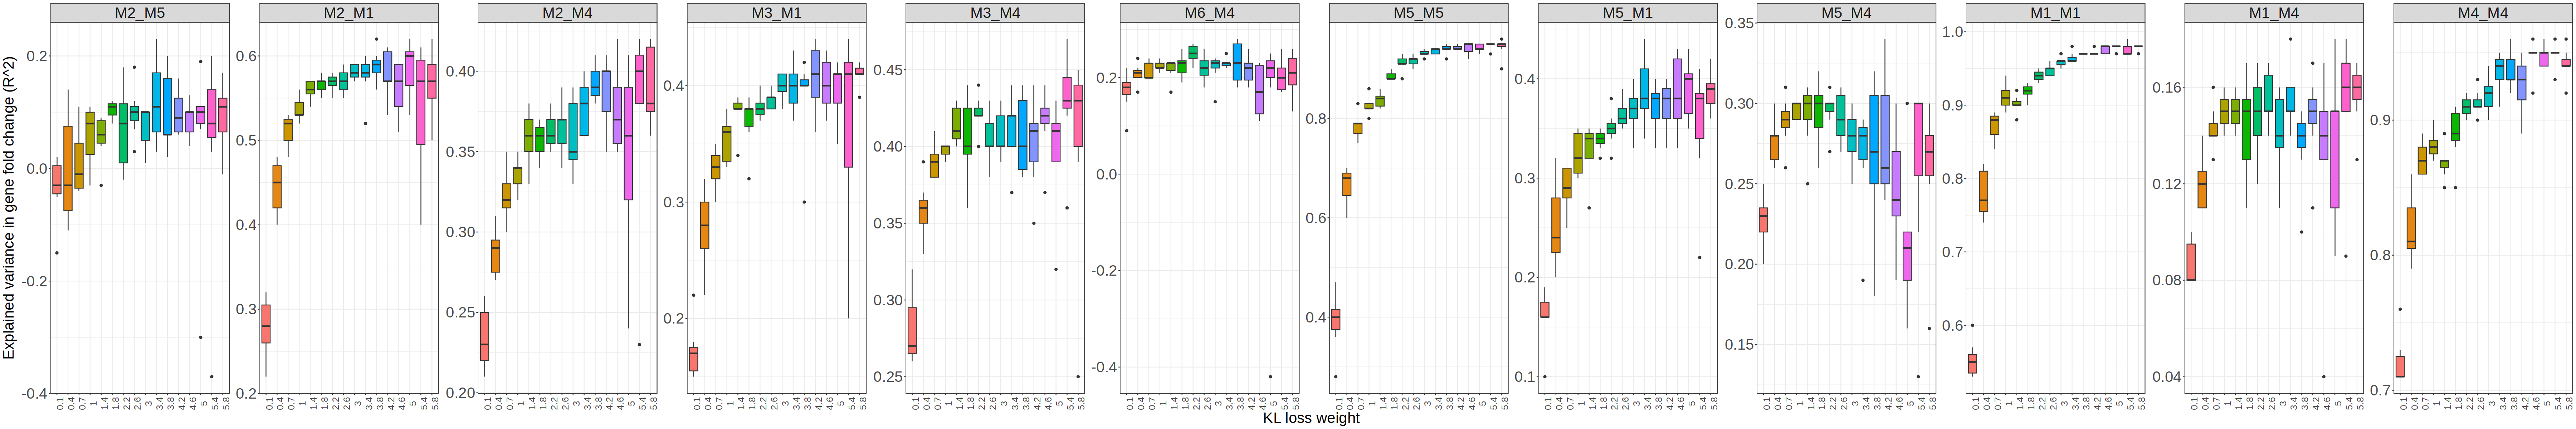

In [5]:
# restored from the live notebook: allMyR2sSelected_1 was never assigned here
allMyR2sSelected_1 = allR2s[allR2s$Group %ni% c("K0_K0",
                                              "K0_K1","K0_K2","K1_K1", "K1_K2","K1_K3", "K2_K2", "K2_K3", "K2_K4"),]
allMyR2sSelected_1 = allMyR2sSelected_1[allMyR2sSelected_1$alpha %in% c(0.1, 0.4, 0.7, 1, 1.4, 1.8,
                                                                        2.2, 2.6, 3, 3.4,3.8, 4.2, 4.6, 5, 5.4, 5.8),]

options(repr.plot.width=60, repr.plot.height=10)

#pdf("./../SupplementaryFigures/S_7D.pdf", width = 60, height = 10)
ggplot(data=allMyR2sSelected_1, aes(x=alphaFactor, y=R2, group=alphaFactor, fill=alphaFactor)) +
  facet_wrap(~GroupLabel, scales="free", nrow = 1)+
  geom_boxplot()+
  theme_bw()+theme(axis.text.x = element_text(size = 15, angle=90),
                   axis.text.y = element_text(size = 25),
                   axis.title = element_text(size = 25),
                   strip.text=element_text(size = 25),
                   legend.position="none")+ylab("Explained variance in gene fold change (R^2)")+
                   xlab("KL loss weight")

#dev.off()

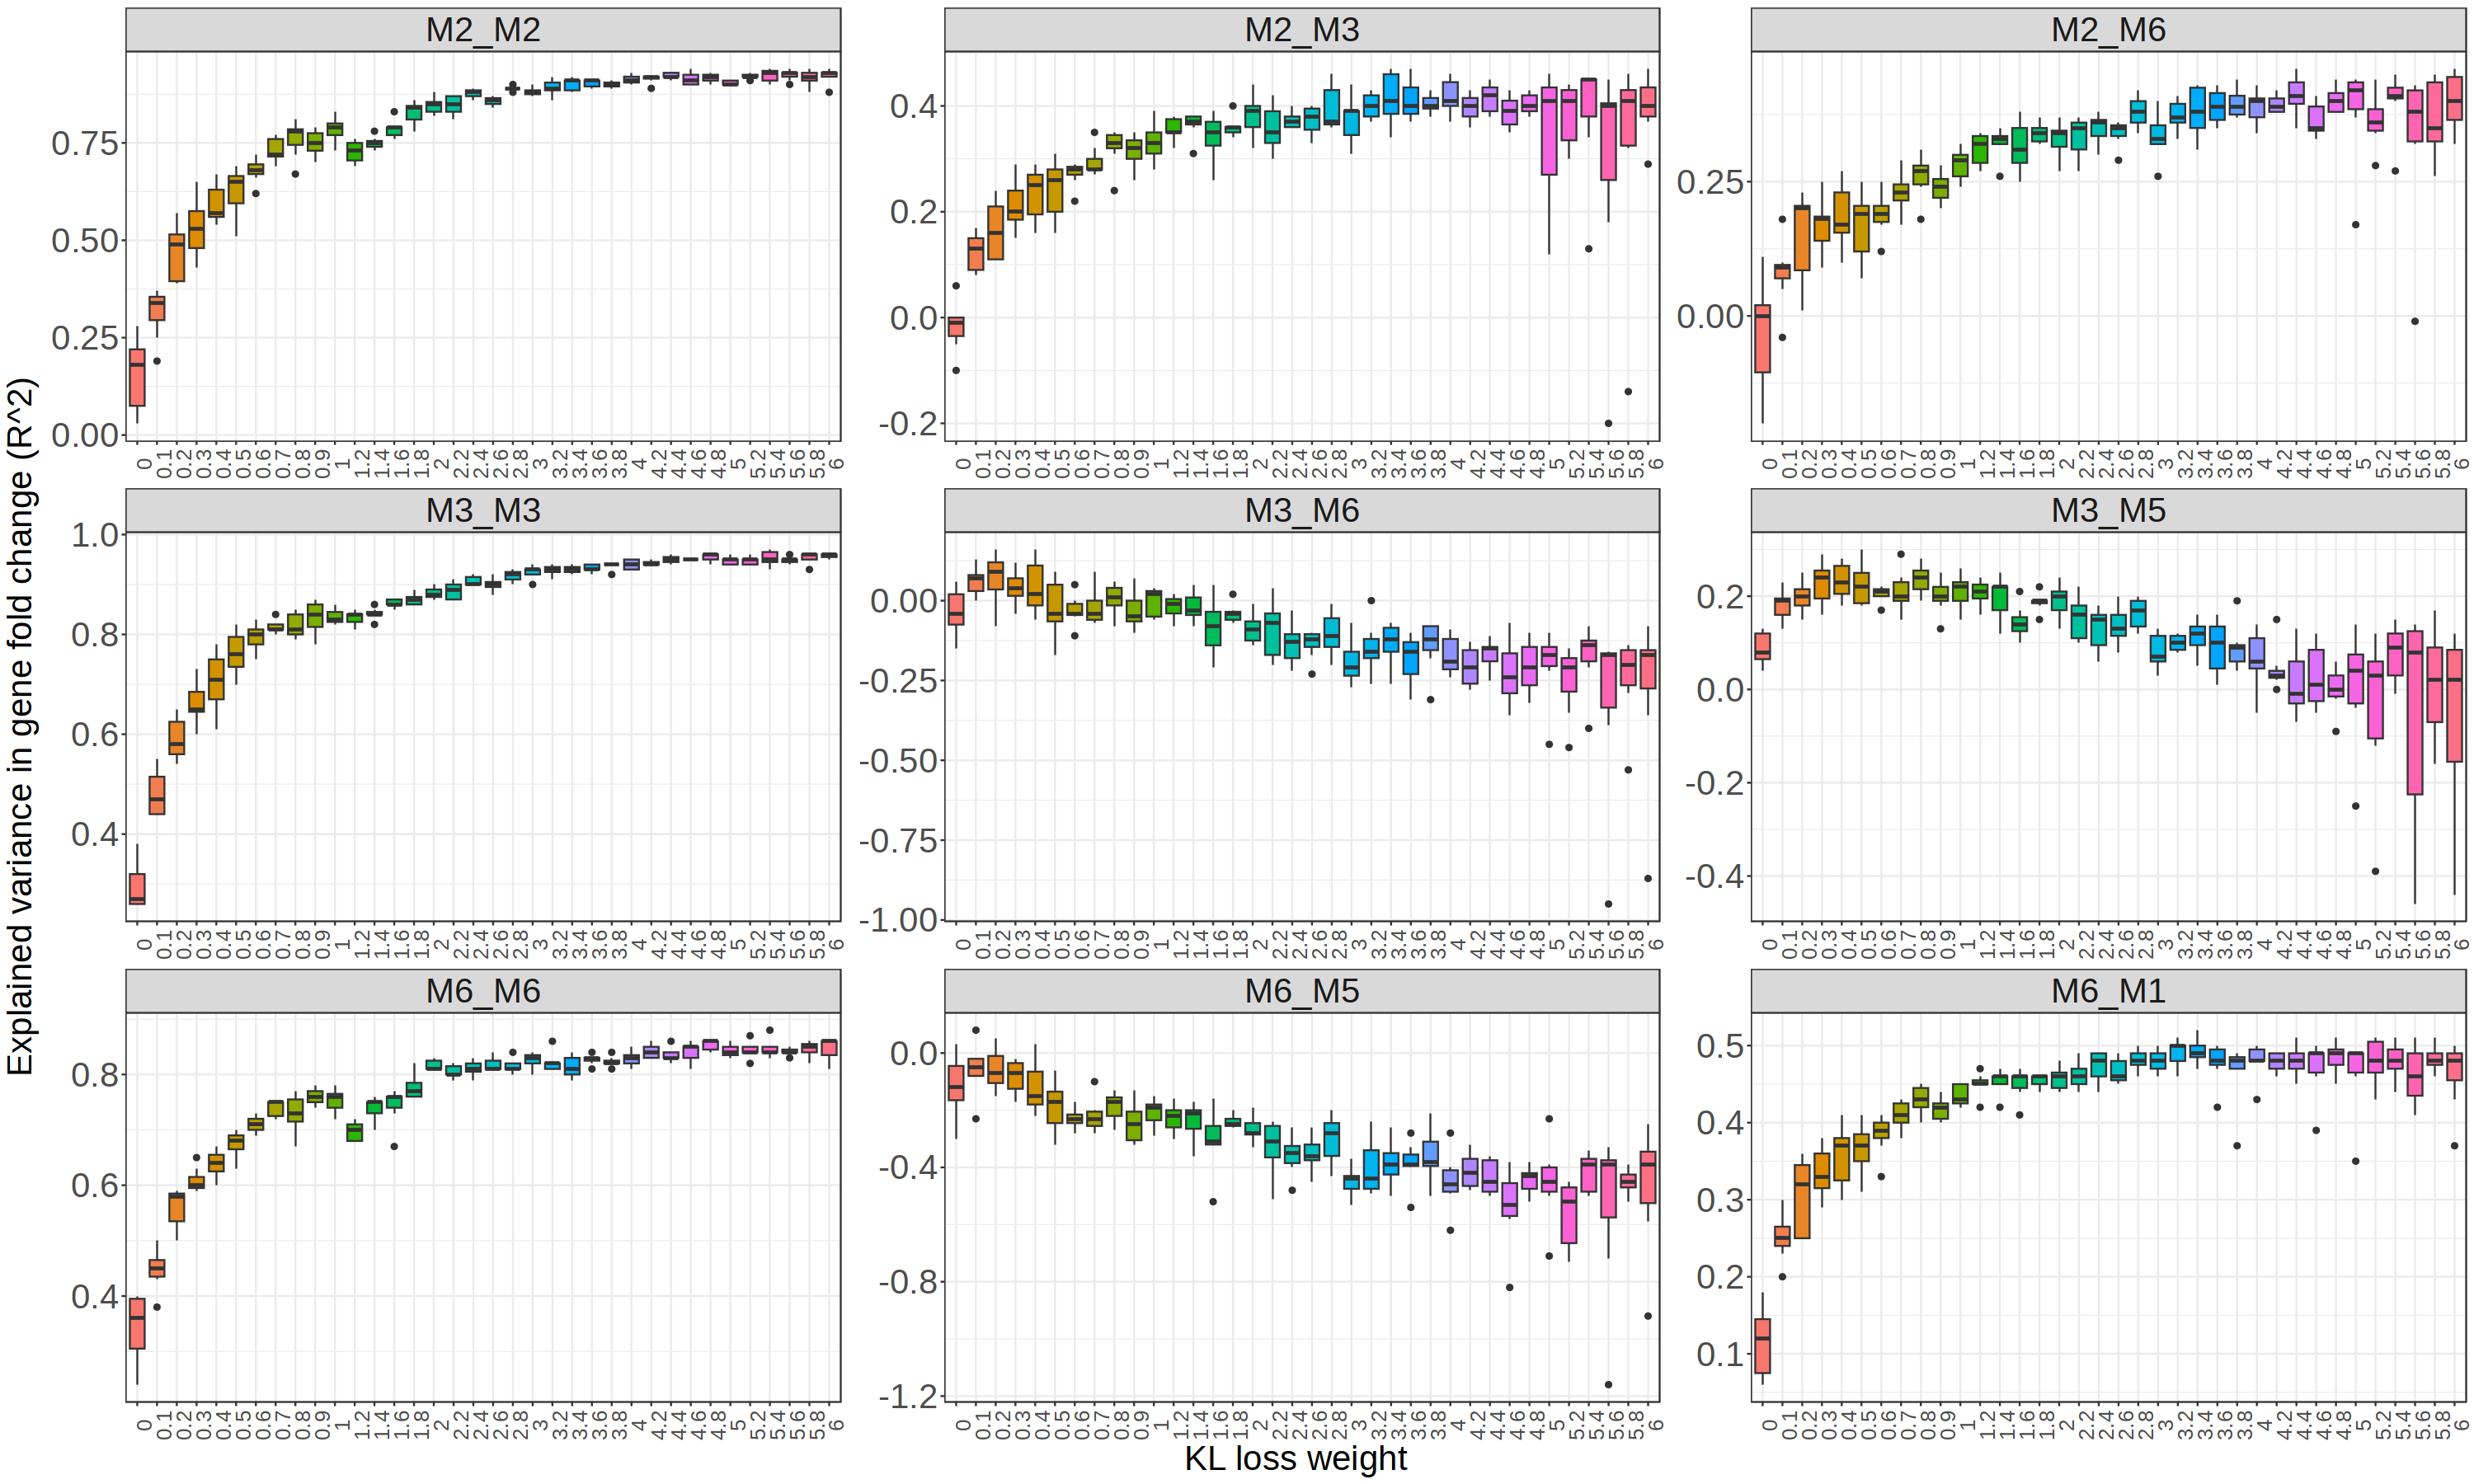

In [6]:
# The nine same-module and adjacent pairs, on the same panels as above.
allMyR2sSelected = allR2s[allR2s$Group %in% c("K0_K0",
                                              "K0_K1",
                                              "K0_K2",
                                              "K1_K1",
                                              "K1_K2",
                                              "K1_K3",
                                              "K2_K2",
                                              "K2_K3",
                                              "K2_K4"),]

options(repr.plot.width=25, repr.plot.height=15)

p <- ggplot(data=allMyR2sSelected, aes(x=alphaFactor, y=R2, group=alphaFactor, fill=alphaFactor)) +
  facet_wrap(~GroupLabel, scales="free", ncol = 3)+
  geom_boxplot()+
  theme_bw()+theme(axis.text.x = element_text(size = 15, angle=90),
                   axis.text.y = element_text(size = 25),
                   axis.title = element_text(size = 25),
                   strip.text=element_text(size = 25),
                   legend.position="none")+ylab("Explained variance in gene fold change (R^2)")+
                   xlab("KL loss weight")

# The original wrote this to ./../Figure_5D.pdf, which lands outside this
# folder and names a panel Figure5_CD produces. Shown here rather than saved;
# give it a filename of its own if it should be written.
p

In [7]:
allSgnR2s$Group = paste0(allSgnR2s$Group1,"_",allSgnR2s$Group2)
allSgnR2s$alphaFactor <- factor(allSgnR2s$alpha)
allSgnR2s$GroupLabel <- groupLabel(allSgnR2s$Group)


In [8]:
# Also restored: allSgnR2s_1 was filtered from itself and never assigned. The
# alpha subset is the one the panel above uses.
allSgnR2s_1 = allSgnR2s[allSgnR2s$alpha %in% c(0.1, 0.4, 0.7, 1, 1.4, 1.8,
                                               2.2, 2.6, 3, 3.4, 3.8, 4.2, 4.6, 5, 5.4, 5.8),]
allSgnR2s_1 = allSgnR2s_1[allSgnR2s_1$Group %in% c("K0_K1", "K0_K2", "K1_K2", "K1_K3", "K2_K3", "K2_K4", "K3_K4"),]

agg_record_73459415 
                  2

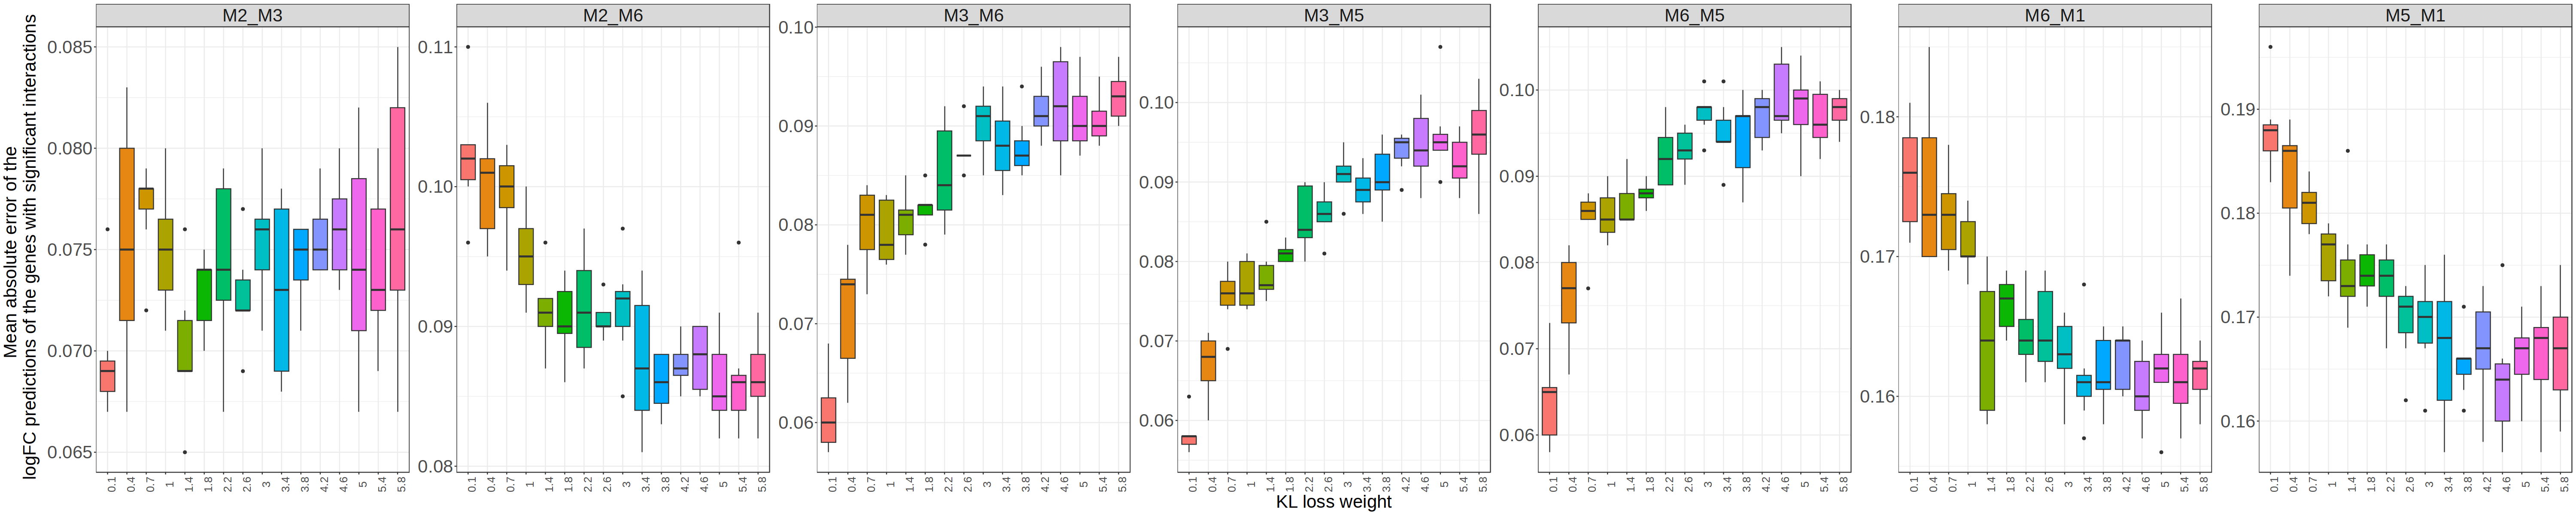

In [9]:
options(repr.plot.width=50, repr.plot.height=10)

p <- ggplot(data=allSgnR2s_1, aes(x=alphaFactor, y=SignMAE, group=alphaFactor, fill=alphaFactor)) +
  facet_wrap(~GroupLabel, scales="free", nrow = 1)+
  geom_boxplot()+
  theme_bw()+theme(axis.text.x = element_text(size = 15, angle=90),
                   axis.text.y = element_text(size = 25),
                   axis.title = element_text(size = 25),
                   strip.text=element_text(size = 25),
                   legend.position="none")+ylab("Mean absolute error of the \n logFC predictions of the genes with significant interactions")+
                   xlab("KL loss weight")

pdf("figures/S_7E.pdf", width = 50, height = 10)
print(p)
dev.off()

p   # show it in the notebook as well as saving it